<a href="https://colab.research.google.com/github/Yukoku115/Multifractal-analysis-in-Urban-cities/blob/main/VQD_O2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NQCC Hackathon 2025 - Part 1: Tutorial Mode
## Computing Ground State ($T_0$) & First Excited State ($S_1$) of $O_2$ using VQE & VQD

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenBioSim/nqcc-hackathon-2025/blob/main/VQD-O2-hackathon.ipynb)

This notebook implements:
1. **Variational Quantum Eigensolver (VQE)** to find the triplet ground state ($T_0$) energy of molecular oxygen ($O_2$).
2. **Variational Quantum Deflation (VQD)** with a SWAP-test overlap penalty to compute the first singlet excited state ($S_1$) energy.
3. **Vertical Excitation Energy** calculation ($\Delta E = E_{S_1} - E_{T_0} \approx 1.467\text{ eV}$) and verification against exact diagonalization and experimental values.


In [1]:
# Install dependencies when running in Google Colab
import sys
if "google.colab" in sys.modules:
    print("Installing dependencies on Google Colab...")
    !pip install -q pennylane pennylane-lightning openfermion openfermionpyscf pyscf optax
    print("Installation complete!")


Installing dependencies on Google Colab...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 609.8 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 47.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━

### Step 1: System and Geometry Setup
We define the $O_2$ molecule with bond length $r = 2.30$ Bohr near its equilibrium geometry, choosing an active space of 2 electrons in 3 spatial orbitals (6 spin-orbitals / qubits).

In [2]:
import jax.core
try:
    from jax.extend.core import concrete_or_error
    jax.core.concrete_or_error = concrete_or_error
except (ImportError, AttributeError):
    pass

import pennylane as qml
from pennylane import qchem
import jax
from jax import numpy as jnp
import numpy as np
from functools import partial

# Active space configuration
active_electrons = 2
active_orbitals = 3

symbols = ["O", "O"]
r = 2.30  # Bond length in Bohr
coordinates = jnp.array([[0.0, 0.0, 0.0], [0.0, 0.0, r]])



### Step 2: Build Molecular Hamiltonian using OpenFermion / PySCF

In [3]:
import pyscf
from pyscf import scf, mp, ci, cc, fci

In [4]:
molecule = qchem.Molecule(symbols, coordinates)
H, qubits = qchem.molecular_hamiltonian(
    molecule,
    active_electrons=active_electrons,
    active_orbitals=active_orbitals,
    method="openfermion"
)
print(f"Hamiltonian terms: {len(H)}, Number of qubits: {qubits}")


Hamiltonian terms: 34, Number of qubits: 6


The Hamiltonian has 34 Pauli strings, but which Pauli terms have the biggest coefficients?



### Step 3: Initial State Preparation & Excitations (UCCSD Ansatz)

In [5]:
# Unpack coefficients and operators using H.terms()
coeffs, ops = H.terms()

# Sort terms by absolute coefficient magnitude
sorted_terms = sorted(zip(coeffs, ops), key=lambda x: abs(x[0]), reverse=True)

print("--- Top 5 Dominant Hamiltonian Terms ---")
for coeff, op in sorted_terms[:5]:
    print(f"Coeff: {float(coeff):+10.4f}  |  Operator: {op}")

--- Top 5 Dominant Hamiltonian Terms ---
Coeff:  -146.3758  |  Operator: I()
Coeff:    -0.5574  |  Operator: Z(4)
Coeff:    -0.5574  |  Operator: Z(5)
Coeff:    -0.2807  |  Operator: Z(0)
Coeff:    -0.2807  |  Operator: Z(1)


In [9]:
coeffs, ops = H.terms()
sorted_terms = sorted(zip(coeffs, ops), key=lambda x:abs(x[0]), reverse=True)
for coeff, op in sorted_terms[:5]:
  print (coeff, op)

-146.37580145703492 I()
-0.5574014556131037 Z(4)
-0.5574014556131037 Z(5)
-0.28072634738579505 Z(0)
-0.280726347385795 Z(1)


In [10]:
from pennylane import AllSinglesDoubles

singles, doubles = qchem.excitations(active_electrons, qubits)
hf = qchem.hf_state(active_electrons, qubits)
init_state = hf
n_params = len(singles) + len(doubles)

print("Hartree-Fock state:", hf)
print("Singles excitations:", singles)
print("Doubles excitations:", doubles)
print(f"Total ansatz parameters: {n_params}")

try:
    dev = qml.device("lightning.qubit", wires=qubits)
except Exception:
    dev = qml.device("default.qubit", wires=qubits)

@qml.qnode(dev, interface="jax")
def circuit(parameters):
    AllSinglesDoubles(parameters, range(qubits), init_state, singles, doubles)
    return qml.expval(H)


Hartree-Fock state: [1 1 0 0 0 0]
Singles excitations: [[0, 2], [0, 4], [1, 3], [1, 5]]
Doubles excitations: [[0, 1, 2, 3], [0, 1, 2, 5], [0, 1, 3, 4], [0, 1, 4, 5]]
Total ansatz parameters: 8


Wire allocations: 6
Total gates: 1
Gate counts:
- AllSinglesDoubles: 1
Measurements:
- expval(Sum(num_wires=6, num_terms=34)): 1
Depth: 1


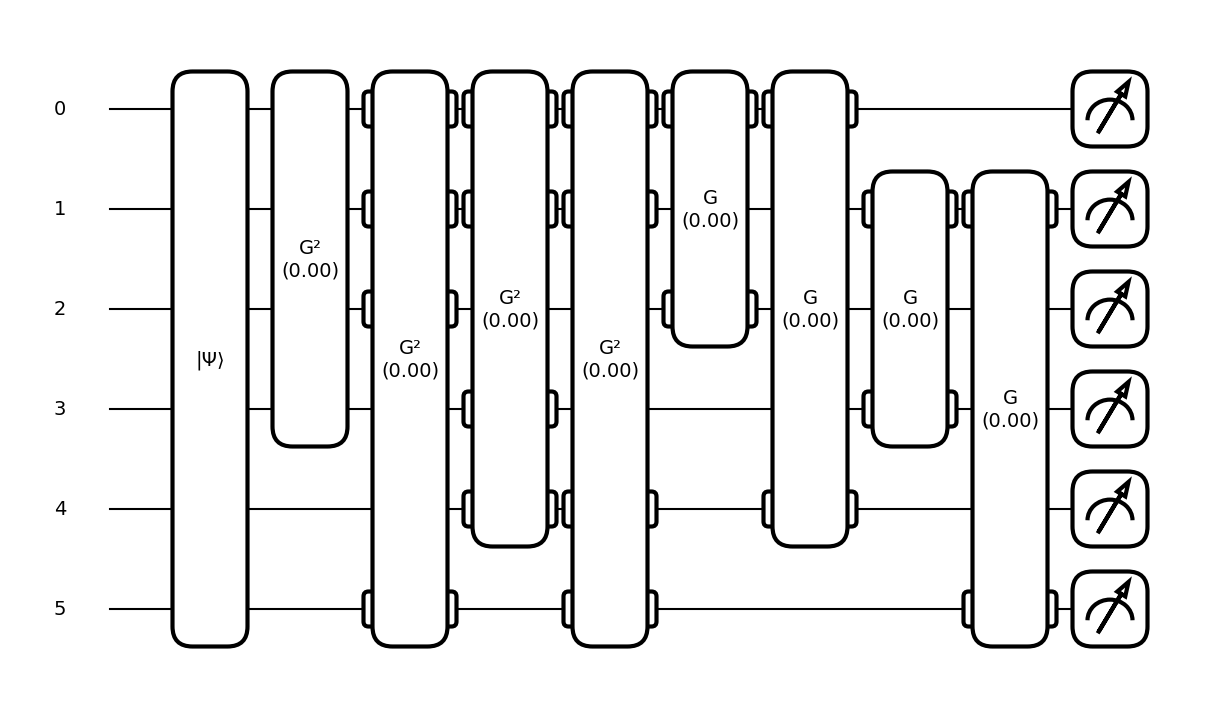

In [18]:
import matplotlib.pyplot as plt
specs = qml.specs(circuit)(np.zeros(n_params))
print(specs["resources"])


@qml.qnode(dev)
def get_initial_state():
    qml.BasisState(hf, wires=range(qubits))
    return qml.state()
decomp_circuit = qml.transforms.decompose(circuit, max_expansion=1)
fig,ax = qml.draw_mpl(decomp_circuit, decimals=2)(np.zeros(n_params))
plt.show()

Here, to visualise the circuit, we see that there is 6 qubits (horizontal line) representing the spin orbitals. While there is 8 G operations, each gate has one angle $\theta$ giving a total of 8 params.  

The left box $|{\Psi}\rangle$ prepares the reference HF state as $|110000\rangle$

### Step 4: Ground State VQE Optimization ($T_0$ Triplet)

In [19]:
import optax

# Optimizer
opt = optax.sgd(learning_rate=0.8) # optax is DeepMind's optimization lib for JAX

# Initialize random gate parameters
np.random.seed(42)
init_vals = np.random.rand(n_params)
init_params = jnp.array(init_vals)

def update_step(params, opt_state):
    grads = jax.grad(circuit)(params)
    updates, opt_state = opt.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state

opt_state = opt.init(init_params)
params = init_params
energy = 0.0
prev_energy = energy

print("Running VQE Ground State Optimization...")
for i in range(101):
    energy = float(circuit(params))
    if i % 10 == 0:
        print(f"Step {i:3d}: Energy = {energy:.8f} Ha")

    if abs(energy - prev_energy) < 1e-6 and i > 0:
        print(f"--> Converged at step {i}!")
        break
    prev_energy = energy

    params, opt_state = update_step(params, opt_state)


ground_state_energy = energy
ground_state_params = params
print(ground_state_params)
print(f"\nFinal Ground State Energy (T0): {ground_state_energy:.8f} Ha")

Running VQE Ground State Optimization...
Step   0: Energy = -147.35560608 Ha
Step  10: Energy = -147.57414246 Ha
Step  20: Energy = -147.59780884 Ha
Step  30: Energy = -147.61227417 Ha
Step  40: Energy = -147.62213135 Ha
Step  50: Energy = -147.62763977 Ha
Step  60: Energy = -147.63031006 Ha
Step  70: Energy = -147.63150024 Ha
Step  80: Energy = -147.63201904 Ha
Step  90: Energy = -147.63224792 Ha
--> Converged at step 94!
[1.3246460e+00 4.8438431e-04 1.7499077e+00 1.8238329e-03 1.5238210e+00
 1.7431254e-03 4.7918051e-04 4.0529454e-03]

Final Ground State Energy (T0): -147.63229370 Ha


### Step 5: Verify Ground State Spin $\langle S^2 \rangle$
For a triplet state ($S=1$), the expected value is $\langle S^2 \rangle = S(S+1) = 2$.

In [27]:
S2 = qchem.spin2(active_electrons, qubits)
@qml.qnode(dev, interface="jax")
def S2_exp_value(parameters):
    AllSinglesDoubles(parameters, range(qubits), init_state, singles, doubles)
    return qml.expval(S2)

s2_gs = float(S2_exp_value(ground_state_params))
print(f"Ground state <S^2> = {s2_gs:.4f} (Expected ~2.0 for Triplet T0)")


Ground state <S^2> = 1.9966 (Expected ~2.0 for Triplet T0)


### Step 6: Define Parameterized Ansatz for Excited State Search

In [22]:
@partial(qml.transforms.decompose, max_expansion=1)
def ansatz(theta, wires):
    s_mapped = [[wires[i] for i in single] for single in singles]
    d_mapped = [[wires[i] for i in double] for double in doubles]
    AllSinglesDoubles(theta, wires, hf, s_mapped, d_mapped)

theta_sample = np.random.rand(n_params)
print(qml.draw(ansatz, decimals=2)(theta_sample, range(qubits)))


0: ─╭|Ψ⟩─╭G²(0.94)─╭G²(0.00)─╭G²(0.99)─╭G²(0.62)─╭G(0.14)─╭G(0.65)───────────────────┤  
1: ─├|Ψ⟩─├G²(0.94)─├G²(0.00)─├G²(0.99)─├G²(0.62)─│────────│────────╭G(0.06)─╭G(0.72)─┤  
2: ─├|Ψ⟩─├G²(0.94)─├G²(0.00)─│─────────│─────────╰G(0.14)─│────────│────────│────────┤  
3: ─├|Ψ⟩─╰G²(0.94)─│─────────├G²(0.99)─│──────────────────│────────╰G(0.06)─│────────┤  
4: ─├|Ψ⟩───────────│─────────╰G²(0.99)─├G²(0.62)──────────╰G(0.65)──────────│────────┤  
5: ─╰|Ψ⟩───────────╰G²(0.00)───────────╰G²(0.62)────────────────────────────╰G(0.72)─┤  


### Step 7: Variational Quantum Deflation (VQD) with SWAP Test
To find the excited state orthogonal to the ground state, we optimize:
$$\mathcal{L}(\theta) = \langle \psi(\theta) | H | \psi(\theta) \rangle + \beta |\langle \psi(\theta) | \psi_{\text{GS}} \rangle|^2$$
where the overlap is measured with a SWAP test circuit on an ancilla qubit.

Initial overlap with ground state: 0.0578


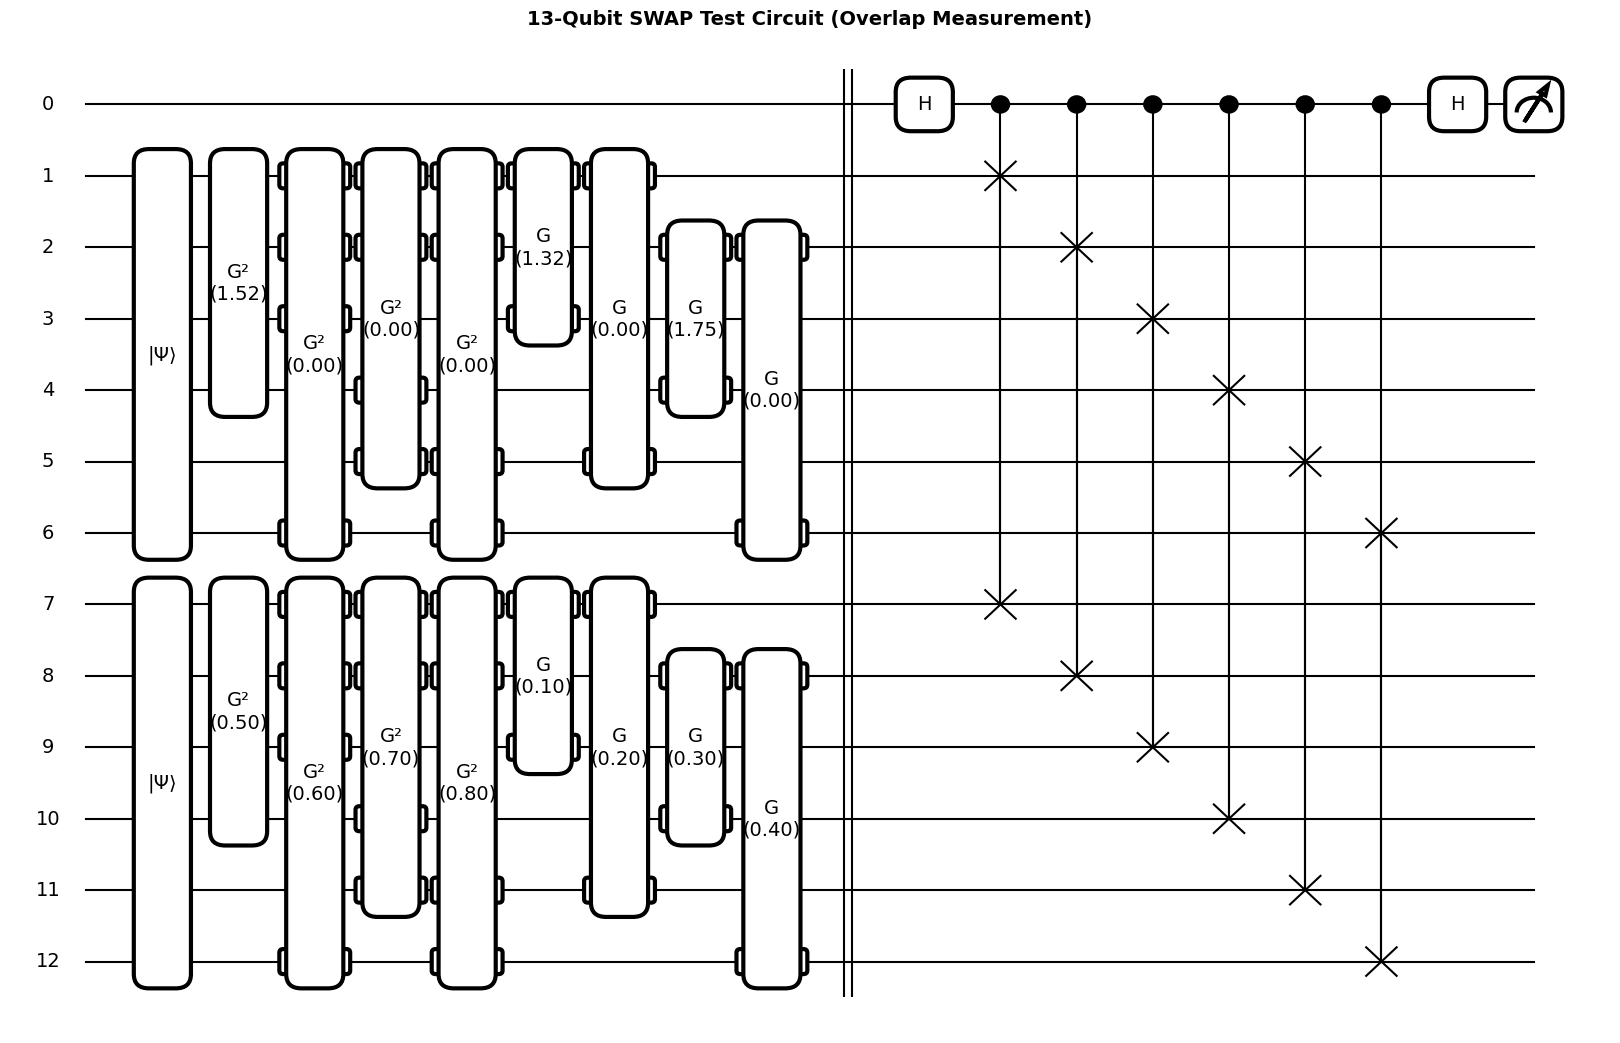

In [30]:
try:
    dev_swap = qml.device("lightning.qubit", wires=2 * qubits + 1)
except Exception:
    dev_swap = qml.device("default.qubit", wires=2 * qubits + 1)

@partial(qml.transforms.decompose, max_expansion=1)
@qml.qnode(dev_swap, interface="jax")
def swap_test(params):
    ansatz(ground_state_params, range(1, qubits + 1))
    ansatz(params, range(qubits + 1, 2 * qubits + 1))
    qml.Barrier()
    qml.Hadamard(wires=0)
    for i in range(qubits):
        qml.CSWAP(wires=[0, 1 + i + qubits, 1 + i])
    qml.Hadamard(wires=0)
    return qml.expval(qml.Z(0))


@qml.qnode(dev_swap, interface="jax")
def expected_value(theta):
    ansatz(theta, range(qubits))
    return qml.expval(H)

def loss_f(theta, beta):
    return expected_value(theta) + beta * swap_test(theta)

init_theta = jnp.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
print(f"Initial overlap with ground state: {float(swap_test(init_theta)):.4f}")

import matplotlib.pyplot as plt
fig, ax = qml.draw_mpl(swap_test, decimals=2)(init_theta)
fig.set_size_inches(16, 10)
plt.title(
    "13-Qubit SWAP Test Circuit (Overlap Measurement)",
    fontsize=14,
    fontweight="bold",
)
plt.show()


### Step 8: Optimize First Excited State ($S_1$ Singlet)

In [24]:
theta = jnp.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
beta = 2.0
opt_vqd = optax.sgd(learning_rate=0.4)
opt_state = opt_vqd.init(theta)

energy_history = [float(loss_f(theta, beta))]
conv_tol = 1e-6
max_iterations = 100

for n in range(max_iterations):
    gradient = jax.grad(loss_f)(theta, beta)
    updates, opt_state = opt_vqd.update(gradient, opt_state)
    theta = optax.apply_updates(theta, updates)
    current_loss = float(loss_f(theta, beta))
    energy_history.append(current_loss)

    if n % 10 == 0:
        print(f"Step {n:3d}: Loss = {current_loss:.8f} Ha, Energy = {float(expected_value(theta)):.8f} Ha, Overlap = {float(swap_test(theta)):.5f}")

    if abs(energy_history[-1] - energy_history[-2]) < conv_tol:
        print(f"Converged at step {n}!")
        break

excited_energy = float(expected_value(theta))
print(f"\nEstimated Excited State Energy (S1): {excited_energy:.8f} Ha")


Step   0: Loss = -147.37281799 Ha, Energy = -147.41200256 Ha, Overlap = 0.01960
Step  10: Loss = -147.54292297 Ha, Energy = -147.54295349 Ha, Overlap = 0.00001
Step  20: Loss = -147.56497192 Ha, Energy = -147.56497192 Ha, Overlap = 0.00000
Step  30: Loss = -147.57046509 Ha, Energy = -147.57046509 Ha, Overlap = 0.00000
Step  40: Loss = -147.57250977 Ha, Energy = -147.57250977 Ha, Overlap = 0.00000
Step  50: Loss = -147.57366943 Ha, Energy = -147.57366943 Ha, Overlap = 0.00000
Step  60: Loss = -147.57452393 Ha, Energy = -147.57452393 Ha, Overlap = 0.00000
Step  70: Loss = -147.57522583 Ha, Energy = -147.57522583 Ha, Overlap = 0.00000
Step  80: Loss = -147.57579041 Ha, Energy = -147.57579041 Ha, Overlap = 0.00000
Step  90: Loss = -147.57626343 Ha, Energy = -147.57626343 Ha, Overlap = 0.00000

Estimated Excited State Energy (S1): -147.57662964 Ha


### Step 9: Verify Excited State Spin $\langle S^2 \rangle$
For a singlet state ($S=0$), the expected value is $\langle S^2 \rangle = 0$.

In [28]:
s2_es = float(S2_exp_value(theta))
print(f"Excited state <S^2> = {s2_es:.4f} (Expected ~0.0 for Singlet S1)")


Excited state <S^2> = 0.0030 (Expected ~0.0 for Singlet S1)


### Step 10: Vertical Excitation Energy & Benchmark Comparison

In [29]:
# Conversion factor: 1 Hartree = 27.2114 eV
HA_TO_EV = 27.2114

delta_E_ha = excited_energy - ground_state_energy
delta_E_ev = delta_E_ha * HA_TO_EV

# Exact diagonalisation of H
H_mat = qml.matrix(H)
exact_eigs = np.sort(np.linalg.eigvalsh(H_mat))
exact_gs = exact_eigs[0]
exact_es = exact_eigs[3]  # First distinct singlet eigenvalue
exact_delta_ha = exact_es - exact_gs
exact_delta_ev = exact_delta_ha * HA_TO_EV

print("=" * 60)
print("          TUTORIAL MODE - FINAL RESULTS SUMMARY")
print("=" * 60)
print(f"Ground State (T0 Triplet) Energy:   {ground_state_energy:.8f} Ha  (<S^2>={s2_gs:.3f})")
print(f"Excited State (S1 Singlet) Energy:  {excited_energy:.8f} Ha  (<S^2>={s2_es:.3f})")
print(f"Energy Difference (Delta E):        {delta_E_ha:.8f} Ha")
print(f"VQD Vertical Excitation Energy:     {delta_E_ev:.4f} eV")
print(f"Exact Vertical Excitation Energy:   {exact_delta_ev:.4f} eV")
print("-" * 60)
print("Benchmark Comparison Table:")
print("  Method            Excitation Energy (eV)")
print(f"  Your VQD run:     {delta_E_ev:.3f} eV")
print(f"  Exact in subspace:{exact_delta_ev:.3f} eV  (ca. 1.467 eV)")
print("  CCSD(T)/STO-3G:   1.334 eV")
print("  HF/STO-3G:        2.278 eV")
print("  Experiment:       0.980 eV")
print("=" * 60)


          TUTORIAL MODE - FINAL RESULTS SUMMARY
Ground State (T0 Triplet) Energy:   -147.63229370 Ha  (<S^2>=1.997)
Excited State (S1 Singlet) Energy:  -147.57662964 Ha  (<S^2>=0.003)
Energy Difference (Delta E):        0.05566406 Ha
VQD Vertical Excitation Energy:     1.5147 eV
Exact Vertical Excitation Energy:   1.4675 eV
------------------------------------------------------------
Benchmark Comparison Table:
  Method            Excitation Energy (eV)
  Your VQD run:     1.515 eV
  Exact in subspace:1.467 eV  (ca. 1.467 eV)
  CCSD(T)/STO-3G:   1.334 eV
  HF/STO-3G:        2.278 eV
  Experiment:       0.980 eV


The HF/STO-3G: gives 2.278eV. this is the simplest classical result, which ignores electron correlationi (they only feel an average cloud). This is the worst method yet because it doesn't allow electrons to correlate and avoid each other.  

Exact in subspace (1.467 eV): This is the mathematical limit i.e. bruteforce diagonalising the matrix.  

CCSD(T) / STO-3G (1.334 eV): Coupled Cluster with Singles, Doubles, and perturbative Triples. This is the most accurate classical algorithm chemists use.